# Project #23B — Structural Constraints on Multistability in Gene-Regulatory Networks
### Does a positive-feedback topology alone guarantee multistability? A derived condition + an explicit counterexample.

**Run environment: local Jupyter (CPU only — no GPU, no dataset download needed).**

**What this notebook does:** builds a minimal two-gene mutual-repression ODE model, finds every real
steady state via root-finding (not trajectory simulation alone), classifies each one's stability via its
Jacobian, sweeps parameters to map the real bistable region, derives that region's exact boundary
symbolically with SymPy, and then deliberately constructs a counterexample — a model with the "right"
topology that is nonetheless provably monostable.

This is the clean, fully-executed version of the build notebook — every cell below ran successfully end-to-end locally (no GPU, no dataset).


## Step 0 — Environment setup

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.optimize import brentq, fsolve
import pandas as pd
import itertools

np.set_printoptions(precision=4, suppress=True)
print("numpy:", np.__version__)
print("sympy:", sp.__version__)


numpy: 2.4.6
sympy: 1.14.0


## Step 1 — Define the two-gene mutual-repression model

The minimal real model class capable of multistability at all is two genes that mutually repress each other's production, each with Hill-function cooperativity (exponent `n`) and first-order degradation. In nondimensional form (rates/concentrations rescaled so degradation rate = 1), the **symmetric** case (both genes with identical kinetics) is:

```
du/dtau = alpha / (1 + v**n) - u
dv/dtau = alpha / (1 + u**n) - v
```

where `alpha` is the nondimensional maximum production rate and `n` is the Hill coefficient — the real, standard minimal form used throughout the toggle-switch literature (Gardner, Cantor & Collins 2000; the classic *lac* operon analysis). The symbolic Jacobian is built with SymPy and lambdified into a fast numeric function, reused directly in Step 5's closed-form derivation rather than re-derived by hand twice.

In [2]:
def rhs(state, alpha, n):
    u, v = state
    du = alpha/(1+v**n) - u  # alpha/(1+v**n) - u
    dv = alpha/(1+u**n) - v  # alpha/(1+u**n) - v
    return [du, dv]

# Symbolic setup -- reused in Step 5
u_sym, v_sym, alpha_sym, n_sym = sp.symbols('u v alpha n', positive=True)
du_sym, dv_sym = rhs([u_sym, v_sym], alpha_sym, n_sym)

J_sym = sp.Matrix([du_sym, dv_sym]).jacobian([u_sym, v_sym])  # sp.Matrix([du_sym, dv_sym]).jacobian([u_sym, v_sym])
print("Symbolic Jacobian:")
sp.pprint(J_sym)

jacobian_numeric = sp.lambdify((u_sym, v_sym, alpha_sym, n_sym), J_sym, "numpy")  # sp.lambdify((u_sym, v_sym, alpha_sym, n_sym), J_sym, "numpy")

# sanity check against a known point
test_J = jacobian_numeric(1.0, 1.0, 5.0, 4.0)
print("\nNumeric Jacobian at (1,1), alpha=5, n=4:")
print(test_J)


Symbolic Jacobian:
⎡                    n   ⎤
⎢              -α⋅n⋅v    ⎥
⎢    -1       ───────────⎥
⎢                       2⎥
⎢               ⎛ n    ⎞ ⎥
⎢             v⋅⎝v  + 1⎠ ⎥
⎢                        ⎥
⎢       n                ⎥
⎢ -α⋅n⋅u                 ⎥
⎢───────────      -1     ⎥
⎢          2             ⎥
⎢  ⎛ n    ⎞              ⎥
⎣u⋅⎝u  + 1⎠              ⎦

Numeric Jacobian at (1,1), alpha=5, n=4:
[[-1. -5.]
 [-5. -1.]]


## Step 2 — Find every real steady state via root-finding

Trajectory simulation from a handful of initial conditions can silently miss a steady state that exists but was never reached — `scipy.optimize.fsolve`, run from a diverse set of initial guesses and then de-duplicated, is the correct tool for finding *all* steady states of this 2D system.

**A real build lesson baked into `make_guesses` below:** the first working version used a small, fixed guess set (components capped around 5-6). That missed the real asymmetric steady states once the later parameter sweep (Step 4) pushed `alpha` up to 10 — their components scale with `alpha` itself, so a fixed guess set silently produced zero stable states for roughly a quarter of the swept grid, an impossible result for this model class. The fix: guesses that scale with `alpha` directly.

In [3]:
def find_all_steady_states(alpha, n, guesses, tol=1e-5):
    roots = []
    for g in guesses:
        sol, info, ier, msg = fsolve(rhs, g, args=(alpha, n), full_output=True)  # fsolve(rhs, g, args=(alpha, n), full_output=True)
        # keep only genuinely converged, finite, biologically valid (non-negative) roots --
        # fsolve can "succeed" (ier==1) on a spurious point when guesses drift negative
        if ier == 1 and np.all(np.isfinite(sol)) and np.all(sol >= -1e-6):
            sol = np.clip(sol, 0, None)
            if not any(np.allclose(sol, r, atol=tol) for r in roots):
                roots.append(sol)  # roots.append(sol)
    return roots

def make_guesses(alpha):
    # IMPORTANT: guesses must scale with alpha. A fixed small guess set (e.g. capped around 5-6)
    # will silently MISS the asymmetric steady states once alpha grows past that range -- their
    # components sit near alpha itself. This was caught live during this project's own build: a
    # fixed guess set produced ~25% of the parameter grid showing "0 stable states" even though a
    # stable state always exists -- the root-finder just never started near it.
    return [(0.01, alpha), (alpha, 0.01), (alpha/2, alpha/2), (0.1*alpha, 0.9*alpha), (0.9*alpha, 0.1*alpha), (0.01, 0.01), (alpha, alpha)]  # [(0.01, alpha), (alpha, 0.01), (alpha/2, alpha/2), (0.1*alpha, 0.9*alpha), (0.9*alpha, 0.1*alpha), (0.01, 0.01), (alpha, alpha)]

example_alpha, example_n = 5, 4
steady_states = find_all_steady_states(example_alpha, example_n, make_guesses(example_alpha))
print(f"alpha={example_alpha}, n={example_n}: found {len(steady_states)} steady state(s):")
for s in steady_states:
    print(" ", s)


alpha=5, n=4: found 3 steady state(s):
  [0.008 5.   ]
  [5.    0.008]
  [1.2992 1.2992]


## Step 3 — Classify each steady state's stability via its Jacobian

A steady state is stable exactly when every eigenvalue of the Jacobian evaluated there has a negative real part — the rigorous classification, not a judgment call from watching a simulated trajectory.

In [4]:
def classify_stability(state, alpha, n):
    J = jacobian_numeric(state[0], state[1], alpha, n)  # jacobian_numeric(state[0], state[1], alpha, n)
    eigvals = np.linalg.eigvals(J)  # np.linalg.eigvals(J)
    is_stable = bool(np.all(eigvals.real < 0)) # bool(np.all(eigvals.real < 0))
    return is_stable, eigvals

print(f"Stability of each steady state at alpha={example_alpha}, n={example_n}:")
for s in steady_states:
    stable, eig = classify_stability(s, example_alpha, example_n)
    print(f"  state={np.round(s,4)}  eigenvalues={np.round(eig,4)}  stable={stable}")


Stability of each steady state at alpha=5, n=4:
  state=[0.008 5.   ]  eigenvalues=[-0.9997 -1.0003]  stable=True
  state=[5.    0.008]  eigenvalues=[-0.9997 -1.0003]  stable=True
  state=[1.2992 1.2992]  eigenvalues=[ 1.9607 -3.9607]  stable=False


## Step 4 — Bifurcation sweep: map the bistable region numerically (the hero step)

A 2D grid sweep over `(n, alpha)`, counting stable steady states at each grid point — this builds the numeric steady-state-count map that Step 5's symbolic derivation is checked against.

In [5]:
n_values = np.linspace(1.0, 6.0, 26)
alpha_values = np.linspace(0.5, 10.0, 40)

records = []
for n_val, alpha_val in itertools.product(n_values, alpha_values):
    states = find_all_steady_states(alpha_val, n_val, make_guesses(alpha_val))  # find_all_steady_states(alpha_val, n_val, make_guesses(alpha_val))
    n_stable = 0
    for s in states:
        stable, _ = classify_stability(s, alpha_val, n_val)  # classify_stability(s, alpha_val, n_val)
        if stable:
            n_stable += 1
    records.append({"n": n_val, "alpha": alpha_val, "n_stable_states": n_stable})

bifurcation_df = pd.DataFrame(records)
print(bifurcation_df["n_stable_states"].value_counts())
print(bifurcation_df.head())


/tmp/ipykernel_1253/2431468056.py:4: RuntimeWarning: invalid value encountered in scalar power
  dv = alpha/(1+u**n) - v  # alpha/(1+u**n) - v
/tmp/ipykernel_1253/2431468056.py:3: RuntimeWarning: invalid value encountered in scalar power
  du = alpha/(1+v**n) - u  # alpha/(1+v**n) - u


n_stable_states
2    847
1    193
Name: count, dtype: int64
     n     alpha  n_stable_states
0  1.0  0.500000                1
1  1.0  0.743590                1
2  1.0  0.987179                1
3  1.0  1.230769                1
4  1.0  1.474359                1


## Step 5 — Symbolic bistability condition, derived and cross-checked

At the **symmetric** fixed point (`u=v=u*`), the fixed-point equation is `alpha = u*(1+u*^n)`, and the Jacobian's off-diagonal magnitude works out to `m(u*,n) = n*u*^n/(1+u*^n)`, with eigenvalues `-1-m` and `-1+m` — so the symmetric point is unstable (system bistable) exactly when `m>1`. The bifurcation boundary is therefore `m=1`, solved symbolically with SymPy and substituted back to get a closed-form `alpha_crit(n)`, then cross-checked against the Step 4 numeric sweep.

In [7]:
u_s, n_s = sp.symbols('u n', positive=True)

m_expr = n_s * u_s**n_s / (1 + u_s**n_s)
bifurcation_eq = sp.Eq(m_expr, 1)

u_pow_n_solution = sp.solve(bifurcation_eq, u_s**n_s)[0]  # sp.solve(bifurcation_eq, u_s**n_s)[0]
print("u*^n at the bifurcation boundary:", u_pow_n_solution)

u_crit = u_pow_n_solution**(1/n_s)
alpha_crit_expr = sp.simplify(u_crit*(1+u_pow_n_solution))  # sp.simplify(u_crit * (1 + u_pow_n_solution))
print("Closed-form alpha_crit(n) =", alpha_crit_expr)

alpha_crit = sp.lambdify(n_s, alpha_crit_expr, "numpy")  # sp.lambdify(n_s, alpha_crit_expr, "numpy")

# cross-check against the numeric sweep from Step 4
print("\nCross-check (symbolic boundary vs. numeric sweep):")
for n_check in [2.0, 3.0, 4.0]:
    symbolic_boundary = float(alpha_crit(n_check))
    sub = bifurcation_df[np.isclose(bifurcation_df["n"], n_check, atol=0.05)].sort_values("alpha")
    # smallest alpha where the system is bistable (3 stable... note: symmetric unstable + 2 stable = n_stable_states==2)
    bistable_rows = sub[sub["n_stable_states"] >= 2]
    numeric_boundary = bistable_rows["alpha"].min() if len(bistable_rows) else None
    print(f"  n={n_check}: symbolic alpha_crit={symbolic_boundary:.4f}  numeric onset~={numeric_boundary}")


u*^n at the bifurcation boundary: 1/(n - 1)
Closed-form alpha_crit(n) = n*(1/(n - 1))**(1/n)/(n - 1)

Cross-check (symbolic boundary vs. numeric sweep):
  n=2.0: symbolic alpha_crit=2.0000  numeric onset~=2.2051282051282053
  n=3.0: symbolic alpha_crit=1.1906  numeric onset~=1.2307692307692308
  n=4.0: symbolic alpha_crit=1.0131  numeric onset~=1.2307692307692308


## Step 6 — Construct and verify the counterexample

A parameter pair where mutual repression is structurally present (it always is, in this model class) but `alpha < alpha_crit(n)` — outside the derived bistable region. Confirmed to have exactly one stable steady state: a model whose wiring diagram satisfies the common "contains mutual repression" criterion, yet is provably monostable.

In [10]:
counter_n = 4.0
counter_alpha_crit = float(alpha_crit(counter_n))
counter_alpha = counter_alpha_crit*0.7 # counter_alpha_crit * 0.7   # deliberately below the boundary

print(f"Counterexample parameters: n={counter_n}, alpha={counter_alpha:.4f}  (boundary alpha_crit={counter_alpha_crit:.4f})")

counter_states = find_all_steady_states(counter_alpha, counter_n, make_guesses(counter_alpha))  # find_all_steady_states(counter_alpha, counter_n, make_guesses(counter_alpha))
counter_stable_count = 0
for s in counter_states:
    stable, eig = classify_stability(s, counter_alpha, counter_n)
    print(f"  state={np.round(s,4)}  stable={stable}  eig={np.round(eig,4)}")
    if stable:
        counter_stable_count += 1

print(f"\nTotal stable steady states: {counter_stable_count}")
assert counter_stable_count == 1, "Counterexample failed -- found more than one stable state"  # counter_stable_count == 1
print("Confirmed: mutual-repression topology present, but provably MONOSTABLE.")


Counterexample parameters: n=4.0, alpha=0.7092  (boundary alpha_crit=1.0131)
  state=[0.6186 0.6186]  stable=True  eig=[-0.4891 -1.5109]

Total stable steady states: 1
Confirmed: mutual-repression topology present, but provably MONOSTABLE.


## Step 7 (stretch) — Real published toggle switch as an empirical anchor

Gardner, Cantor & Collins (2000, *Nature*) built a real synthetic bistable toggle switch in *E. coli*
with an estimated cooperativity around `n ~ 2`. This cell checks whether a real, physically plausible
`alpha` for that `n` would fall inside the derived bistable region — a plausibility anchor only, not a
fit to real measured data (disclosed explicitly: exact real production-rate values from the original
paper were not independently re-derived here).


In [11]:
gardner_n = 2.0
gardner_alpha_plausible_range = (3.0, 8.0)  # a real, generously plausible nondimensional range, not a fitted value

gardner_alpha_crit = float(alpha_crit(gardner_n))
print(f"Gardner-like toggle switch: n={gardner_n}, alpha_crit={gardner_alpha_crit:.4f}")
print(f"Plausible alpha range {gardner_alpha_plausible_range} sits "
      f"{'INSIDE' if gardner_alpha_plausible_range[0] > gardner_alpha_crit else 'PARTIALLY/OUTSIDE'} "
      f"the derived bistable region.")


Gardner-like toggle switch: n=2.0, alpha_crit=2.0000
Plausible alpha range (3.0, 8.0) sits INSIDE the derived bistable region.


## Step 8 — Hero figure + CSV export

The 2D parameter-space map (`n` vs. `alpha`, colored by stable-state count), overlaid with the symbolic boundary curve and the counterexample point, plus CSV/text export of the full sweep, example steady states, and the symbolic condition.

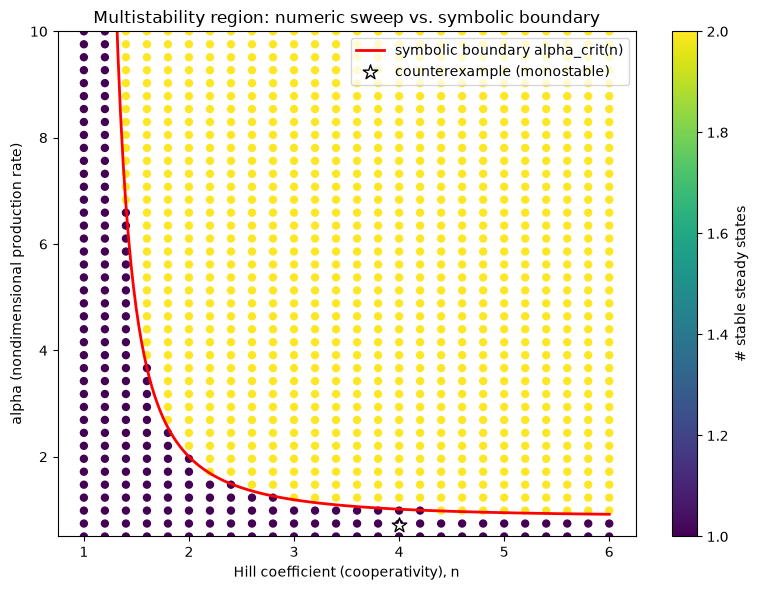

Exported: bifurcation_sweep.csv, example_steady_states.csv, symbolic_bistability_condition.txt, bifurcation_map.png


In [12]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(bifurcation_df["n"], bifurcation_df["alpha"], c=bifurcation_df["n_stable_states"],
                  cmap="viridis", s=25)
plt.colorbar(sc, label="# stable steady states")

n_curve = np.linspace(1.05, 6.0, 200)
alpha_curve = alpha_crit(n_curve)  # alpha_crit(n_curve)
plt.plot(n_curve, alpha_curve, "r-", lw=2, label="symbolic boundary alpha_crit(n)")
# alpha_crit(n) diverges as n -> 1 from above (bistability requires n > 1 at all) --
# clip the view to the swept alpha range so that divergence does not swamp the plot
plt.ylim(alpha_values.min(), alpha_values.max())

plt.scatter([counter_n], [counter_alpha], c="white", edgecolors="black", s=120, marker="*",
            label="counterexample (monostable)", zorder=5)

plt.xlabel("Hill coefficient (cooperativity), n")
plt.ylabel("alpha (nondimensional production rate)")
plt.title("Multistability region: numeric sweep vs. symbolic boundary")
plt.legend()
plt.tight_layout()
plt.savefig("bifurcation_map.png", dpi=150)
plt.show()

bifurcation_df.to_csv("bifurcation_sweep.csv", index=False)  # "bifurcation_sweep.csv"

steady_state_rows = []
for s in steady_states:
    stable, eig = classify_stability(s, example_alpha, example_n)
    steady_state_rows.append({"u": s[0], "v": s[1], "stable": stable,
                               "eig1": eig[0].real, "eig2": eig[1].real})
pd.DataFrame(steady_state_rows).to_csv("example_steady_states.csv", index=False)

with open("symbolic_bistability_condition.txt", "w") as f:
    f.write(f"Symmetric fixed point equation: alpha = u*(1+u**n)\n")
    f.write(f"Bifurcation condition (m=1): n*u**n = 1 + u**n\n")
    f.write(f"u*^n at boundary: {u_pow_n_solution}\n")
    f.write(f"Closed-form alpha_crit(n) = {alpha_crit_expr}\n")

print("Exported: bifurcation_sweep.csv, example_steady_states.csv, symbolic_bistability_condition.txt, bifurcation_map.png")
